# Medidas estadísticas y su error
**Objetivo:** distinguir valor medio, dispersión de mediciones e incertidumbre del promedio. Ejemplo de clase: temperaturas mínimas de Estocolmo.

## 1. Leer datos y calcular tendencia central
Los datos del archivo incluyen año, mes, día y temperaturas. En la clase se usa la **columna 4** (índice 4 de Python) para temperatura mínima.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('bmh')

datos = np.genfromtxt('stockholm_td_adj.dat')
T_min = datos[:, 4]
T_min = T_min[np.isfinite(T_min)]
media = np.mean(T_min)
mediana = np.median(T_min)
print(f'N = {len(T_min):,} días; media = {media:.2f} °C; mediana = {mediana:.2f} °C')

N = 77,431 días; media = 5.83 °C; mediana = 5.40 °C


## 2. Varianza, desviación y error estándar
La presentación usa $\sigma^2=\frac1N\sum_i(x_i-\bar x)^2$ y $\delta\bar x=\sigma/\sqrt N$. Son diferentes: **dispersión de cada dato** frente a **precisión estadística del promedio**.

In [2]:
N = len(T_min)
varianza = np.sum((T_min - media)**2) / N
sigma = np.sqrt(varianza)
error_media = sigma / np.sqrt(N)
print(f'Varianza = {varianza:.3f} °C²')
print(f'Desviación estándar = {sigma:.3f} °C')
print(f'Error estándar (fórmula de clase) = {error_media:.4f} °C')
print('Comprobación con NumPy:', np.std(T_min, ddof=0))

Varianza = 68.015 °C²
Desviación estándar = 8.247 °C
Error estándar (fórmula de clase) = 0.0296 °C
Comprobación con NumPy: 8.24713957807167


> **Hipótesis:** los datos corresponden a muchos años y a distintas estaciones. No son repeticiones independientes de una temperatura constante. La fórmula del error estándar se practica aquí **como cálculo**, no como una incertidumbre fiable de una temperatura física fija.

## 3. Histograma y rango media ± desviación

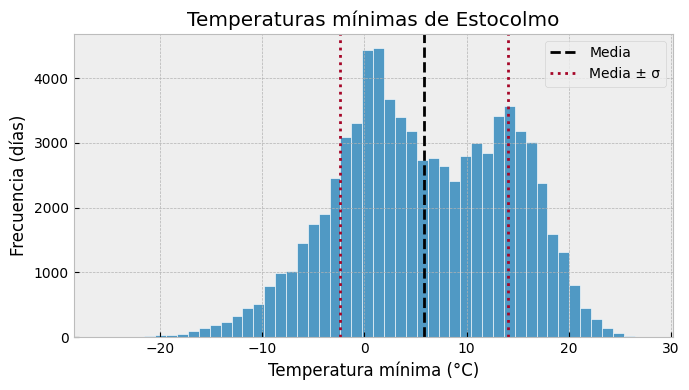

In [3]:
plt.figure(figsize=(7, 4))
plt.hist(T_min, bins=50, edgecolor='white', alpha=0.85)
plt.axvline(media, color='black', ls='--', label='Media')
plt.axvline(media - sigma, color='C1', ls=':', label='Media ± σ')
plt.axvline(media + sigma, color='C1', ls=':')
plt.xlabel('Temperatura mínima (°C)')
plt.ylabel('Frecuencia (días)')
plt.title('Temperaturas mínimas de Estocolmo')
plt.legend()
plt.tight_layout()
plt.show()

**Comprueba:** si hacemos cuatro veces más mediciones **independientes con la misma dispersión**, ¿por qué el error estándar disminuye a la mitad y no a la cuarta parte?